# NLP : Résumé automatique, Question-Réponse et Génération de texte

Ce notebook implémente **trois tâches du NLP** avec des modèles Hugging Face exécutés **entièrement en local** (aucune API cloud : les modèles sont téléchargés une seule fois, puis réutilisables hors ligne) :

| # | Tâche | Modèle | Métriques |
|---|-------|--------|-----------|
| 4 | Résumé automatique (*Summarization*) | `sshleifer/distilbart-cnn-12-6` | ROUGE-1/2/L, BERTScore |
| 5 | Question-Réponse (*Question Answering*) | `distilbert-base-cased-distilled-squad` | Exact Match, F1, match par inclusion |
| 6 | Génération de texte (*Text Generation*) | `distilgpt2` | BLEU, perplexité, Distinct-1/2/3 |

En plus des scores, chaque tâche est **analysée** : heatmap précision/rappel, effet de la longueur maximale, analyse d'erreurs et confiance du QA, surprisal token par token, variabilité selon la graine et la température, temps de réponse et débit.

**Plan** : 0. Installation → 1. Imports → 2. Données → 3. Résumé (+ analyses) → 4. QA (+ analyses) → 5. Génération (+ analyses) → 6. Temps de réponse et vitesse → 7. Récapitulatif et synthèse → 8. Remarques.

> ⏱️ Durée d'exécution indicative sur **CPU** : environ 10 à 15 minutes (les sections 3.4, 5.3 et 6 répètent des générations). Réduisez `MAX_LENGTHS`, `N_SEEDS`, `TEMPERATURES` ou `N_RUNS` pour aller plus vite.

## 0. Installation des dépendances

In [1]:
%pip install -q "transformers>=4.40,<5" torch sentencepiece rouge-score sacrebleu bert-score pandas matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 1. Imports et configuration

In [2]:
import html
import math
import time
import re
import string
import collections

import torch
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display
import sacrebleu
from rouge_score import rouge_scorer
from transformers import (
    pipeline,
    AutoTokenizer,
    AutoModelForCausalLM,
    set_seed,
)

SEED = 42
set_seed(SEED)

DEVICE_STR = "cuda" if torch.cuda.is_available() else "cpu"
DEVICE_ID = 0 if torch.cuda.is_available() else -1   # format attendu par pipeline()
print("Device utilisé :", DEVICE_STR)

# Dossier où les graphiques sont sauvegardés (PNG)
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

LOAD_TIMES = {}   # temps de chargement de chaque modèle (en secondes)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

def sync():
    """Attend la fin des calculs GPU (sans effet sur CPU) pour des chronométrages corrects."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()

Device utilisé : cpu


## 2. Jeu de données d'exemple

Petit jeu de données **intégré** (pas de téléchargement de dataset) afin que le notebook soit autonome.
Chaque article sert à la fois au **résumé** (avec un résumé de référence) et au **QA** (comme contexte).
Pour un vrai benchmark, remplacez ces listes par un extrait local de CNN/DailyMail, SQuAD, etc.

In [3]:
ARTICLES = [
    "The city council approved a plan to install solar panels on all public buildings by 2030. "
    "The project is expected to cost 40 million euros and will cut the city's electricity bill by a third. "
    "Officials said the panels will also create about 200 local jobs during construction. "
    "Critics argued that the money could be better spent on public transport, but the council voted 7 to 2 in favor.",

    "Researchers at a university in Canada followed 2,000 adults for five years to study the link between sleep and memory. "
    "They found that people who slept fewer than six hours a night scored 20 percent lower on memory tests than those who slept seven to eight hours. "
    "The team also noted that regular exercise partly reduced this gap. "
    "The authors recommend that adults aim for at least seven hours of sleep and stay physically active.",

    "A small company released an open source library that lets developers run language models on ordinary laptops without a graphics card. "
    "The library compresses model weights to use less memory and reports speeds of ten tokens per second on a standard processor. "
    "Early users praised the easy installation, while some noted that accuracy drops slightly on complex reasoning tasks.",
]

REFERENCE_SUMMARIES = [
    "The city council approved a 40 million euro plan to put solar panels on all public buildings by 2030, "
    "which should cut electricity costs by a third and create about 200 jobs.",

    "A five-year study of 2,000 adults found that sleeping under six hours reduces memory test scores by 20 percent, "
    "though exercise partly offsets the effect.",

    "A new open source library compresses language models so they run on ordinary laptops at about ten tokens per second, "
    "with easy installation but slightly lower accuracy on complex reasoning.",
]

# (index de l'article-contexte, question, réponse attendue)
QA_SET = [
    (0, "How much will the project cost?", "40 million euros"),
    (0, "By what year will the panels be installed?", "2030"),
    (0, "How did the council vote?", "7 to 2"),
    (1, "How many adults were followed in the study?", "2,000"),
    (1, "How many hours of sleep do the authors recommend?", "at least seven hours"),
    (2, "How many tokens per second does the library reach?", "ten tokens per second"),
]

GEN_PROMPTS = [
    "Artificial intelligence is transforming",
    "In the future, universities will",
    "The most important skill for a data engineer is",
]
GEN_REFERENCES = [
    "the way we work, learn and communicate every day.",
    "rely more on online learning and personalized teaching.",
    "the ability to build reliable and scalable data pipelines.",
]

## 3. Résumé automatique (*Summarization*)

**Principe** : résumé **abstractif** — un modèle séquence-à-séquence (DistilBART) génère un nouveau texte plus court.

**Métrique : ROUGE** (*Recall-Oriented Understudy for Gisting Evaluation*) compare le résumé généré au résumé de référence :
- **ROUGE-1** : recouvrement des mots (unigrammes)
- **ROUGE-2** : recouvrement des paires de mots (bigrammes)
- **ROUGE-L** : plus longue sous-séquence commune

Chaque score est donné en précision / rappel / F1 ; on rapporte le **F1** (entre 0 et 1, plus c'est haut mieux c'est).

In [4]:
SUM_MODEL = "sshleifer/distilbart-cnn-12-6"
_t0 = time.perf_counter()
summarizer = pipeline("summarization", model=SUM_MODEL, device=DEVICE_ID)
LOAD_TIMES["summarization"] = time.perf_counter() - _t0

def summarize(texts, max_length=60, min_length=15):
    """Génère un résumé pour chaque texte (décodage déterministe, beam search)."""
    outputs = summarizer(
        texts,
        max_length=max_length,
        min_length=min_length,
        num_beams=4,
        do_sample=False,
        truncation=True,
    )
    return [o["summary_text"].strip() for o in outputs]

def evaluate_rouge(predictions, references):
    """Moyenne des F1 ROUGE-1 / ROUGE-2 / ROUGE-L sur tout le jeu de données."""
    scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)
    totals = collections.defaultdict(float)
    for pred, ref in zip(predictions, references):
        scores = scorer.score(ref, pred)   # (cible, prédiction)
        for name, s in scores.items():
            totals[name] += s.fmeasure
    return {name: v / len(predictions) for name, v in totals.items()}

summaries = summarize(ARTICLES)
for i, (s, r) in enumerate(zip(summaries, REFERENCE_SUMMARIES), 1):
    print(f"--- Article {i} ---")
    print("Généré   :", s)
    print("Référence:", r, "\n")

rouge_results = evaluate_rouge(summaries, REFERENCE_SUMMARIES)
print("ROUGE (F1 moyen) :", {k: round(v, 4) for k, v in rouge_results.items()})

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

Device set to use cpu


--- Article 1 ---
Généré   : The project is expected to cost 40 million euros and will cut the city's electricity bill by a third . Officials said the panels will also create about 200 local jobs during construction . Critics argued that the money could be better spent on public transport .
Référence: The city council approved a 40 million euro plan to put solar panels on all public buildings by 2030, which should cut electricity costs by a third and create about 200 jobs. 

--- Article 2 ---
Généré   : Researchers at a university in Canada followed 2,000 adults for five years to study the link between sleep and memory . They found that people who slept fewer than six hours a night scored 20 percent lower on memory tests than those who slept seven to eight hours . The authors recommend that adults aim
Référence: A five-year study of 2,000 adults found that sleeping under six hours reduces memory test scores by 20 percent, though exercise partly offsets the effect. 

--- Article 3 ---
G

### 3.1 Visualisation des résultats du résumé

- **Gauche** : scores ROUGE (F1) pour chaque article et en moyenne.
- **Droite** : longueur (en mots) de l'article, du résumé de référence et du résumé généré — permet de vérifier que le modèle compresse comme attendu.

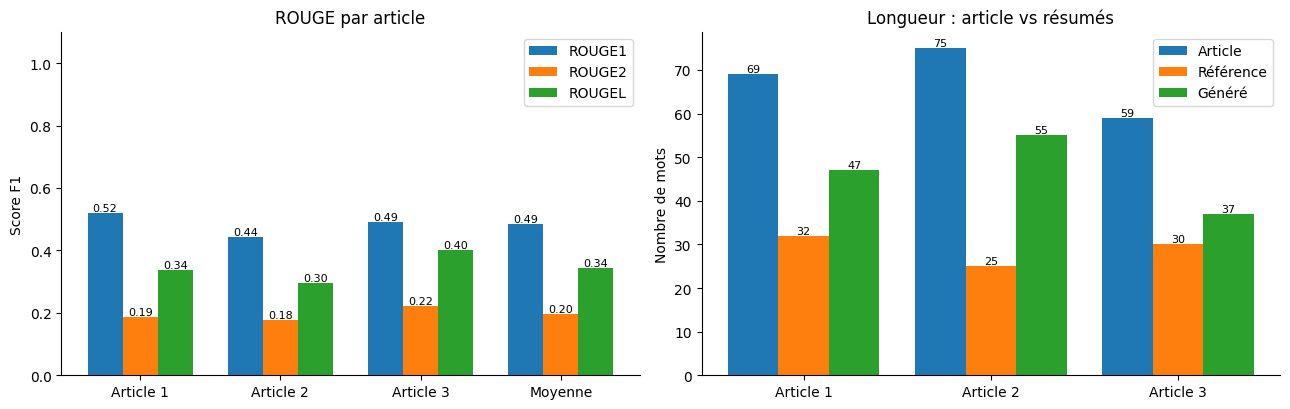

In [5]:
def rouge_per_sample(predictions, references):
    """Scores ROUGE (F1) calculés article par article."""
    scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)
    return [
        {name: s.fmeasure for name, s in scorer.score(ref, pred).items()}
        for pred, ref in zip(predictions, references)
    ]

per_sample = rouge_per_sample(summaries, REFERENCE_SUMMARIES)
labels = [f"Article {i + 1}" for i in range(len(per_sample))] + ["Moyenne"]
x = np.arange(len(labels))
width = 0.25

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))

# (1) ROUGE par article
for j, name in enumerate(["rouge1", "rouge2", "rougeL"]):
    values = [s[name] for s in per_sample] + [rouge_results[name]]
    bars = ax1.bar(x + (j - 1) * width, values, width, label=name.upper())
    ax1.bar_label(bars, fmt="%.2f", fontsize=8)
ax1.set_xticks(x)
ax1.set_xticklabels(labels)
ax1.set_ylim(0, 1.1)
ax1.set_ylabel("Score F1")
ax1.set_title("ROUGE par article")
ax1.legend()

# (2) Longueurs en mots
n_art = len(ARTICLES)
idx = np.arange(n_art)
w = 0.27
lengths = {
    "Article": [len(t.split()) for t in ARTICLES],
    "Référence": [len(t.split()) for t in REFERENCE_SUMMARIES],
    "Généré": [len(t.split()) for t in summaries],
}
for j, (name, vals) in enumerate(lengths.items()):
    bars = ax2.bar(idx + (j - 1) * w, vals, w, label=name)
    ax2.bar_label(bars, fontsize=8)
ax2.set_xticks(idx)
ax2.set_xticklabels([f"Article {i + 1}" for i in range(n_art)])
ax2.set_ylabel("Nombre de mots")
ax2.set_title("Longueur : article vs résumés")
ax2.legend()

plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "summarization_rouge.png"), dpi=150, bbox_inches="tight")
plt.show()

### 3.2 Précision, rappel et F1 (heatmap)

Le F1 cache deux informations : la **précision** (part du résumé généré qui est « juste ») et le **rappel** (part de la référence retrouvée). Un rappel nettement supérieur à la précision indique un résumé **trop long / trop copié** du texte source.

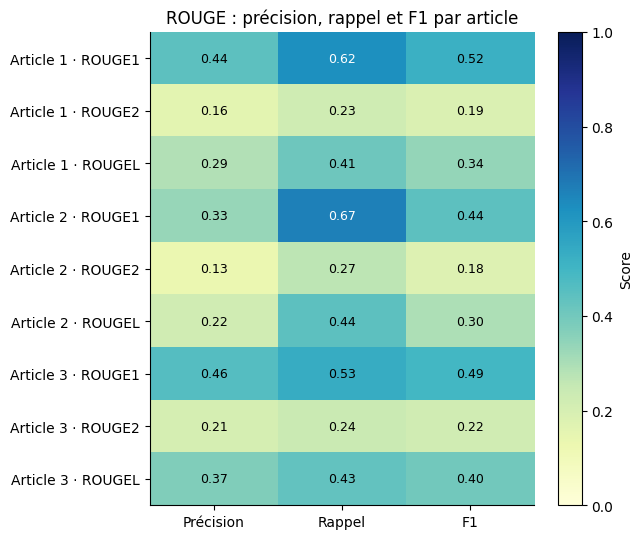

Précision moyenne = 0.29 | Rappel moyen = 0.43
→ rappel > précision : résumés plus longs que nécessaire.


In [6]:
def rouge_full(predictions, references):
    """Précision / rappel / F1 de chaque variante ROUGE, article par article."""
    scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)
    rows = []
    for i, (pred, ref) in enumerate(zip(predictions, references), 1):
        for name, s in scorer.score(ref, pred).items():
            rows.append({"Article": f"Article {i}", "Métrique": name.upper(),
                         "Précision": s.precision, "Rappel": s.recall, "F1": s.fmeasure})
    return pd.DataFrame(rows)

rouge_full_df = rouge_full(summaries, REFERENCE_SUMMARIES)
heat = rouge_full_df.set_index(["Article", "Métrique"])[["Précision", "Rappel", "F1"]]

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(heat.values, cmap="YlGnBu", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(heat.shape[1]))
ax.set_xticklabels(heat.columns)
ax.set_yticks(range(heat.shape[0]))
ax.set_yticklabels([f"{a} · {m}" for a, m in heat.index])
for r in range(heat.shape[0]):
    for c in range(heat.shape[1]):
        v = heat.values[r, c]
        ax.text(c, r, f"{v:.2f}", ha="center", va="center",
                color="white" if v > 0.6 else "black", fontsize=9)
ax.set_title("ROUGE : précision, rappel et F1 par article")
fig.colorbar(im, ax=ax, label="Score")
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "rouge_heatmap.png"), dpi=150, bbox_inches="tight")
plt.show()

mean_p, mean_r = rouge_full_df["Précision"].mean(), rouge_full_df["Rappel"].mean()
print(f"Précision moyenne = {mean_p:.2f} | Rappel moyen = {mean_r:.2f}")
print("→ rappel > précision : résumés plus longs que nécessaire." if mean_r > mean_p
      else "→ précision ≥ rappel : résumés plutôt concis.")

### 3.3 BERTScore : similarité sémantique

ROUGE compte des mots identiques ; **BERTScore** compare les phrases via les embeddings d'un modèle (ici `distilbert-base-uncased`, local après un premier téléchargement d'environ 270 Mo) et reconnaît donc certaines reformulations.

⚠️ Les valeurs **brutes** de BERTScore (sans rééchelonnement) sont naturellement élevées (souvent > 0,8) : servez-vous-en pour **comparer** des systèmes, pas comme score absolu. Si le modèle ne peut pas être téléchargé, la cellule affiche un message et le notebook continue.

In [7]:
bertscore_results = None
try:
    from bert_score import score as bert_score_fn
    P, R, F = bert_score_fn(summaries, REFERENCE_SUMMARIES, model_type="distilbert-base-uncased",
                            lang="en", device=DEVICE_STR, verbose=False)
    bertscore_results = {
        "bertscore_precision": P.mean().item(),
        "bertscore_recall": R.mean().item(),
        "bertscore_f1": F.mean().item(),
    }
    bertscore_per_article = F.tolist()
except Exception as exc:   # dépendance absente, modèle non téléchargeable, etc.
    print("BERTScore indisponible, analyse ignorée :", repr(exc))

if bertscore_results:
    print({k: round(v, 4) for k, v in bertscore_results.items()})
    comparison = pd.DataFrame({
        "ROUGE-1 F1": [s["rouge1"] for s in per_sample],
        "ROUGE-L F1": [s["rougeL"] for s in per_sample],
        "BERTScore F1": bertscore_per_article,
    }, index=[f"Article {i + 1}" for i in range(len(per_sample))])
    display(comparison.round(3))

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

{'bertscore_precision': 0.8345, 'bertscore_recall': 0.8579, 'bertscore_f1': 0.846}


,ROUGE-1 F1,ROUGE-L F1,BERTScore F1
Article 1,0.519,0.338,0.840
Article 2,0.444,0.296,0.826
Article 3,0.492,0.400,0.872


### 3.4 Effet de la longueur maximale (`max_length`)

Avec `max_length=60`, un résumé peut être **coupé en plein milieu d'une phrase**. On fait varier `max_length` et on observe : la qualité (ROUGE), la **complétude** (le résumé se termine-t-il par une ponctuation finale ?) et le **coût** (latence par article).

Your max_length is set to 80, but your input_length is only 77. Since this is a summarization task, where outputs shorter than the input are typically wanted, you might consider decreasing max_length manually, e.g. summarizer('...', max_length=38)
Your max_length is set to 80, but your input_length is only 66. Since this is a summarization task, where outputs shorter than the input are typically wanted, you might consider decreasing max_length manually, e.g. summarizer('...', max_length=33)
Your max_length is set to 100, but your input_length is only 77. Since this is a summarization task, where outputs shorter than the input are typically wanted, you might consider decreasing max_length manually, e.g. summarizer('...', max_length=38)
Your max_length is set to 100, but your input_length is only 83. Since this is a summarization task, where outputs shorter than the input are typically wanted, you might consider decreasing max_length manually, e.g. summarizer('...', max_length=41)
Your m

,ROUGE-1,ROUGE-2,ROUGE-L,Résumés complets (%),Mots générés,Latence moy. (s)
max_length,,,,,,
40,0.540,0.281,0.406,0.000,35.667,6.057
60,0.485,0.195,0.345,66.667,46.333,7.806
80,0.497,0.200,0.344,100.000,44.333,9.655
100,0.497,0.200,0.344,100.000,44.333,7.930


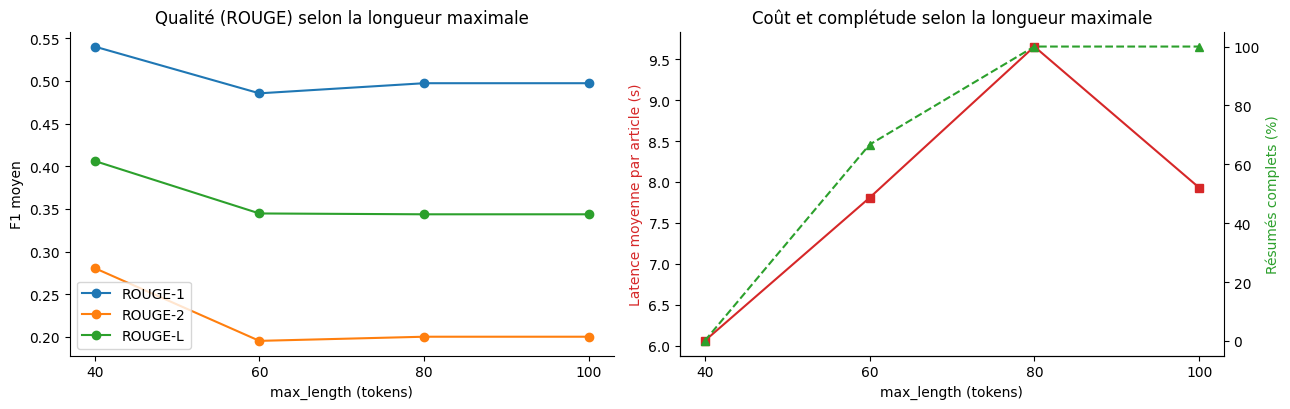

Meilleur ROUGE-L : max_length = 40 (0.406)
Plus petit max_length donnant 100 % de résumés complets : 80


In [8]:
MAX_LENGTHS = [40, 60, 80, 100]

def is_complete(text):
    """Le résumé se termine-t-il par une ponctuation finale (sinon il a été coupé) ?"""
    return text.rstrip().endswith((".", "!", "?"))

sweep_rows = []
for max_len in MAX_LENGTHS:
    preds, times = [], []
    for article in ARTICLES:
        sync()
        t0 = time.perf_counter()
        preds.append(summarize([article], max_length=max_len)[0])
        sync()
        times.append(time.perf_counter() - t0)
    scores = rouge_per_sample(preds, REFERENCE_SUMMARIES)
    sweep_rows.append({
        "max_length": max_len,
        "ROUGE-1": np.mean([s["rouge1"] for s in scores]),
        "ROUGE-2": np.mean([s["rouge2"] for s in scores]),
        "ROUGE-L": np.mean([s["rougeL"] for s in scores]),
        "Résumés complets (%)": 100 * np.mean([is_complete(p) for p in preds]),
        "Mots générés": np.mean([len(p.split()) for p in preds]),
        "Latence moy. (s)": np.mean(times),
    })
sweep_df = pd.DataFrame(sweep_rows).set_index("max_length")
display(sweep_df.round(3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
for col in ["ROUGE-1", "ROUGE-2", "ROUGE-L"]:
    ax1.plot(sweep_df.index, sweep_df[col], marker="o", label=col)
ax1.set_xticks(sweep_df.index)
ax1.set_xlabel("max_length (tokens)")
ax1.set_ylabel("F1 moyen")
ax1.set_title("Qualité (ROUGE) selon la longueur maximale")
ax1.legend()

ax2.plot(sweep_df.index, sweep_df["Latence moy. (s)"], marker="s", color="tab:red")
ax2.set_xticks(sweep_df.index)
ax2.set_xlabel("max_length (tokens)")
ax2.set_ylabel("Latence moyenne par article (s)", color="tab:red")
ax3 = ax2.twinx()
ax3.plot(sweep_df.index, sweep_df["Résumés complets (%)"], marker="^", linestyle="--", color="tab:green")
ax3.set_ylabel("Résumés complets (%)", color="tab:green")
ax3.set_ylim(-5, 105)
ax3.spines["right"].set_visible(True)
ax2.set_title("Coût et complétude selon la longueur maximale")

plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "summarization_max_length.png"), dpi=150, bbox_inches="tight")
plt.show()

best = sweep_df["ROUGE-L"].idxmax()
print(f"Meilleur ROUGE-L : max_length = {best} ({sweep_df.loc[best, 'ROUGE-L']:.3f})")
all_complete = sweep_df[sweep_df["Résumés complets (%)"] == 100]
print("Plus petit max_length donnant 100 % de résumés complets :",
      all_complete.index.min() if len(all_complete) else "aucun dans la plage testée")

## 4. Question-Réponse (*Question Answering*)

**Principe** : QA **extractif** — étant donné un contexte et une question, le modèle (DistilBERT fine-tuné sur SQuAD) prédit le **segment du contexte** qui contient la réponse.

**Métriques (standard SQuAD)** :
- **Exact Match (EM)** : 1 si la réponse prédite est identique à la réponse attendue après normalisation (minuscules, sans ponctuation ni articles), sinon 0.
- **F1** : F1 calculé au niveau des **mots** partagés entre prédiction et référence (récompense les réponses partiellement correctes).

In [9]:
QA_MODEL = "distilbert-base-cased-distilled-squad"
_t0 = time.perf_counter()
qa_pipeline = pipeline("question-answering", model=QA_MODEL, device=DEVICE_ID)
LOAD_TIMES["qa"] = time.perf_counter() - _t0

def normalize_answer(s):
    """Minuscules, suppression de la ponctuation et des articles, espaces normalisés."""
    s = s.lower()
    s = "".join(ch for ch in s if ch not in set(string.punctuation))
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return " ".join(s.split())

def exact_match(prediction, truth):
    return float(normalize_answer(prediction) == normalize_answer(truth))

def f1_score(prediction, truth):
    pred_tokens = normalize_answer(prediction).split()
    true_tokens = normalize_answer(truth).split()
    common = collections.Counter(pred_tokens) & collections.Counter(true_tokens)
    num_same = sum(common.values())
    if len(pred_tokens) == 0 or len(true_tokens) == 0:
        return float(pred_tokens == true_tokens)
    if num_same == 0:
        return 0.0
    precision = num_same / len(pred_tokens)
    recall = num_same / len(true_tokens)
    return 2 * precision * recall / (precision + recall)

def answer_questions(qa_set, contexts):
    """Retourne la liste des réponses prédites pour chaque (contexte, question)."""
    preds = []
    for ctx_idx, question, _ in qa_set:
        out = qa_pipeline(question=question, context=contexts[ctx_idx])
        preds.append(out["answer"])
    return preds

def evaluate_qa(predictions, qa_set):
    em = sum(exact_match(p, gold) for p, (_, _, gold) in zip(predictions, qa_set)) / len(qa_set)
    f1 = sum(f1_score(p, gold) for p, (_, _, gold) in zip(predictions, qa_set)) / len(qa_set)
    return {"exact_match": em, "f1": f1}

qa_preds = answer_questions(QA_SET, ARTICLES)
for (ctx_idx, q, gold), pred in zip(QA_SET, qa_preds):
    print(f"Q : {q}\n   Prédit : {pred!r} | Attendu : {gold!r} | "
          f"EM={exact_match(pred, gold):.0f} F1={f1_score(pred, gold):.2f}")

qa_results = evaluate_qa(qa_preds, QA_SET)
print("\nQA :", {k: round(v, 4) for k, v in qa_results.items()})

config.json:   0%|          | 0.00/473 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/261M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cpu


Q : How much will the project cost?
   Prédit : '40 million euros' | Attendu : '40 million euros' | EM=1 F1=1.00
Q : By what year will the panels be installed?
   Prédit : '2030' | Attendu : '2030' | EM=1 F1=1.00
Q : How did the council vote?
   Prédit : '7 to 2 in favor' | Attendu : '7 to 2' | EM=0 F1=0.75
Q : How many adults were followed in the study?
   Prédit : '2,000' | Attendu : '2,000' | EM=1 F1=1.00
Q : How many hours of sleep do the authors recommend?
   Prédit : 'at least seven' | Attendu : 'at least seven hours' | EM=0 F1=0.86
Q : How many tokens per second does the library reach?
   Prédit : 'ten' | Attendu : 'ten tokens per second' | EM=0 F1=0.40

QA : {'exact_match': 0.5, 'f1': 0.8345}


### 4.1 Visualisation des résultats du QA

Exact Match et F1 pour **chaque question** : une barre F1 > EM signale une réponse partiellement correcte (bon contenu mais segment plus long ou plus court que la référence).

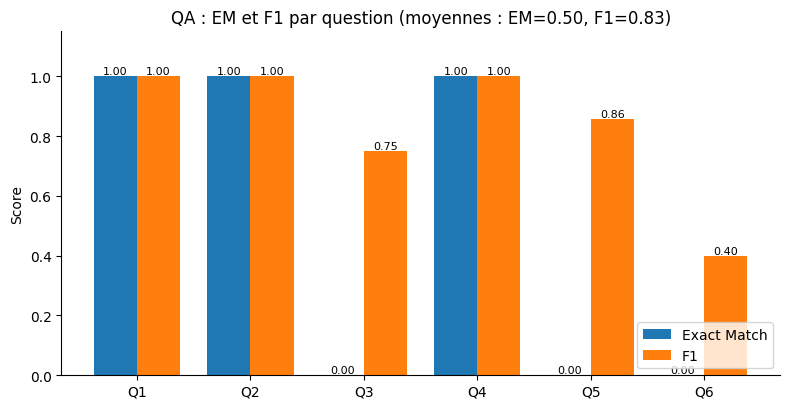

Q1 : How much will the project cost?
Q2 : By what year will the panels be installed?
Q3 : How did the council vote?
Q4 : How many adults were followed in the study?
Q5 : How many hours of sleep do the authors recommend?
Q6 : How many tokens per second does the library reach?


In [10]:
em_scores = [exact_match(p, gold) for p, (_, _, gold) in zip(qa_preds, QA_SET)]
f1_scores = [f1_score(p, gold) for p, (_, _, gold) in zip(qa_preds, QA_SET)]
labels = [f"Q{i + 1}" for i in range(len(QA_SET))]
x = np.arange(len(labels))
width = 0.38

fig, ax = plt.subplots(figsize=(8, 4.2))
b1 = ax.bar(x - width / 2, em_scores, width, label="Exact Match")
b2 = ax.bar(x + width / 2, f1_scores, width, label="F1")
ax.bar_label(b1, fmt="%.2f", fontsize=8)
ax.bar_label(b2, fmt="%.2f", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.15)
ax.set_ylabel("Score")
ax.set_title(f"QA : EM et F1 par question (moyennes : EM={qa_results['exact_match']:.2f}, F1={qa_results['f1']:.2f})")
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "qa_scores.png"), dpi=150, bbox_inches="tight")
plt.show()

for i, (_, question, _) in enumerate(QA_SET, 1):
    print(f"Q{i} : {question}")

### 4.2 Analyse d'erreurs : confiance, positions et type d'erreur

Le pipeline renvoie aussi un **score de confiance** et la **position** (`start`, `end`) de la réponse dans le contexte. On classe chaque réponse :

- `exacte` : identique à la référence ;
- `trop longue` / `trop courte` : la bonne réponse est incluse dans la prédiction (ou l'inverse) → **erreur de frontière** ;
- `incorrecte` : sans rapport avec la référence.

On ajoute le **match par inclusion** : 1 si l'une des deux réponses (normalisées) est contenue dans l'autre. C'est une métrique **indulgente, non standard** : elle peut accepter à tort une réponse trop courte (ex. un seul mot) ; à lire avec l'EM, pas à sa place.

In [11]:
def _is_sublist(small, big):
    """True si la liste de mots `small` apparaît telle quelle dans `big`."""
    n = len(small)
    return n > 0 and any(big[i:i + n] == small for i in range(len(big) - n + 1))

def inclusion_match(prediction, truth):
    p, t = normalize_answer(prediction).split(), normalize_answer(truth).split()
    return float(_is_sublist(p, t) or _is_sublist(t, p))

def error_type(prediction, truth):
    p, t = normalize_answer(prediction).split(), normalize_answer(truth).split()
    if p == t:
        return "exacte"
    if _is_sublist(t, p):
        return "trop longue"
    if _is_sublist(p, t):
        return "trop courte"
    return "incorrecte"

qa_rows = []
for ctx_idx, question, gold in QA_SET:
    out = qa_pipeline(question=question, context=ARTICLES[ctx_idx])
    qa_rows.append({
        "Question": question, "Prédit": out["answer"], "Attendu": gold,
        "EM": exact_match(out["answer"], gold), "F1": f1_score(out["answer"], gold),
        "Inclusion": inclusion_match(out["answer"], gold),
        "Confiance": out["score"], "Erreur": error_type(out["answer"], gold),
        "ctx": ctx_idx, "start": out["start"], "end": out["end"],
    })
qa_df = pd.DataFrame(qa_rows)
qa_results["inclusion_match"] = float(qa_df["Inclusion"].mean())

display(qa_df[["Question", "Prédit", "Attendu", "EM", "F1", "Inclusion", "Confiance", "Erreur"]].round(3))
print(f"EM = {qa_results['exact_match']:.2f} | F1 = {qa_results['f1']:.2f} | Inclusion = {qa_results['inclusion_match']:.2f}")
print("Répartition des types de réponse :", qa_df["Erreur"].value_counts().to_dict())

,Question,Prédit,Attendu,EM,F1,Inclusion,Confiance,Erreur
0,How much will the project cost?,40 million euros,40 million euros,1.0,1.000,1.0,0.969,exacte
1,By what year will the panels be installed?,2030,2030,1.0,1.000,1.0,0.957,exacte
2,How did the council vote?,7 to 2 in favor,7 to 2,0.0,0.750,1.0,0.612,trop longue
3,How many adults were followed in the study?,"2,000","2,000",1.0,1.000,1.0,0.931,exacte
4,How many hours of sleep do the authors recommend?,at least seven,at least seven hours,0.0,0.857,1.0,0.280,trop courte
5,How many tokens per second does the library re...,ten,ten tokens per second,0.0,0.400,1.0,0.734,trop courte


EM = 0.50 | F1 = 0.83 | Inclusion = 1.00
Répartition des types de réponse : {'exacte': 3, 'trop courte': 2, 'trop longue': 1}


### 4.3 Confiance du modèle vs qualité de la réponse

Chaque point est une question : en abscisse la **confiance** du modèle, en ordonnée le **F1**. Un modèle bien calibré a des points en haut à droite (confiant et juste) ; un point en bas à droite serait une erreur **sûre d'elle**.

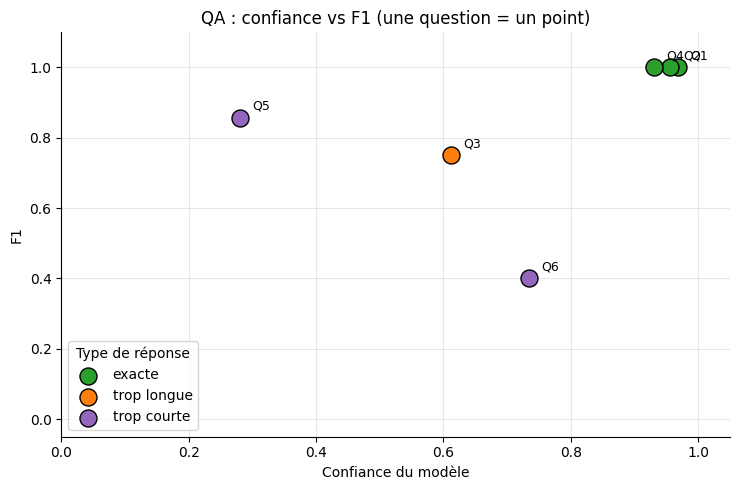

In [12]:
palette = {"exacte": "tab:green", "trop longue": "tab:orange", "trop courte": "tab:purple", "incorrecte": "tab:red"}

fig, ax = plt.subplots(figsize=(7.5, 5))
for kind, color in palette.items():
    sub = qa_df[qa_df["Erreur"] == kind]
    if len(sub):
        ax.scatter(sub["Confiance"], sub["F1"], s=150, color=color, label=kind, edgecolor="black", zorder=3)
for i, r in qa_df.iterrows():
    ax.annotate(f"Q{i + 1}", (r["Confiance"], r["F1"]), textcoords="offset points", xytext=(9, 6), fontsize=9)
ax.set_xlim(0, 1.05)
ax.set_ylim(-0.05, 1.1)
ax.set_xlabel("Confiance du modèle")
ax.set_ylabel("F1")
ax.set_title("QA : confiance vs F1 (une question = un point)")
ax.grid(alpha=0.3)
ax.legend(title="Type de réponse", loc="lower left")
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "qa_confidence.png"), dpi=150, bbox_inches="tight")
plt.show()

### 4.4 Réponses surlignées dans le contexte

Le segment prédit par le modèle est surligné en jaune dans le texte d'origine (✅ exacte · 🟠 trop longue · 🟣 trop courte · ❌ incorrecte).

In [13]:
def highlight_answer(context, start, end):
    """Retourne le contexte en HTML avec le segment [start:end] surligné."""
    return (html.escape(context[:start])
            + "<mark style='background:#ffd54f;color:#000;padding:0 2px'>"
            + html.escape(context[start:end]) + "</mark>"
            + html.escape(context[end:]))

status_icons = {"exacte": "✅", "trop longue": "🟠", "trop courte": "🟣", "incorrecte": "❌"}
blocks = []
for i, r in qa_df.iterrows():
    context = ARTICLES[int(r["ctx"])]
    blocks.append(
        f"<div style='margin-bottom:14px'><b>Q{i + 1}</b> {status_icons[r['Erreur']]} {html.escape(r['Question'])} "
        f"<i>(attendu : {html.escape(r['Attendu'])} · confiance {r['Confiance']:.2f})</i><br>"
        f"{highlight_answer(context, int(r['start']), int(r['end']))}</div>"
    )
display(HTML("".join(blocks)))

## 5. Génération de texte (*Text Generation*)

**Principe** : un modèle de langage causal (DistilGPT-2) continue un *prompt* mot après mot. On compare trois stratégies de décodage :
- **greedy** : prend toujours le token le plus probable (déterministe, souvent répétitif) ;
- **sampling** : échantillonnage *top-p* + température (plus varié, moins prévisible) ;
- **greedy_no_repeat** : greedy avec interdiction de répéter un même trigramme (`no_repeat_ngram_size=3`), correctif simple aux boucles.

**Métriques** :
- **BLEU** (sacreBLEU, 0–100) : recouvrement de n-grammes avec une continuation de référence. Peu fiable pour la génération ouverte (beaucoup de continuations valides), à interpréter avec prudence.
- **Perplexité** du texte généré selon le modèle : plus elle est basse, plus le texte est « probable » pour le modèle (fluidité).
- **Distinct-1 / 2 / 3** : proportion de unigrammes / bigrammes / trigrammes **uniques** dans le texte généré (mesure de la **diversité**, détecte les répétitions).
- **mean_words** : nombre moyen de mots générés (information, pas un score).

In [14]:
GEN_MODEL = "distilgpt2"
_t0 = time.perf_counter()
gen_tokenizer = AutoTokenizer.from_pretrained(GEN_MODEL)
gen_model = AutoModelForCausalLM.from_pretrained(GEN_MODEL).to(DEVICE_STR)
gen_model.eval()
LOAD_TIMES["generation"] = time.perf_counter() - _t0

STRATEGIES = {
    "greedy":   dict(do_sample=False),
    "sampling": dict(do_sample=True, top_p=0.9, temperature=0.8),
    "greedy_no_repeat": dict(do_sample=False, no_repeat_ngram_size=3),   # greedy sans répéter un trigramme
}

def generate_continuation(prompt, max_new_tokens=30, **gen_kwargs):
    """Génère uniquement la continuation (sans répéter le prompt)."""
    inputs = gen_tokenizer(prompt, return_tensors="pt").to(DEVICE_STR)
    with torch.no_grad():
        output_ids = gen_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            pad_token_id=gen_tokenizer.eos_token_id,
            **gen_kwargs,
        )
    new_tokens = output_ids[0][inputs["input_ids"].shape[1]:]
    return gen_tokenizer.decode(new_tokens, skip_special_tokens=True)

def perplexity(text):
    """Perplexité d'un texte selon le modèle de génération : exp(loss moyenne)."""
    enc = gen_tokenizer(text, return_tensors="pt").to(DEVICE_STR)
    with torch.no_grad():
        loss = gen_model(**enc, labels=enc["input_ids"]).loss
    return math.exp(loss.item())

def distinct_n(text, n):
    """Ratio n-grammes uniques / n-grammes totaux (diversité lexicale)."""
    tokens = text.lower().split()
    ngrams = [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]
    return len(set(ngrams)) / len(ngrams) if ngrams else 0.0

def evaluate_generation(prompts, references, strategy_kwargs):
    """Génère pour chaque prompt puis calcule BLEU, perplexité et Distinct-n (moyennes)."""
    set_seed(SEED)
    continuations = [generate_continuation(p, **strategy_kwargs) for p in prompts]
    bleu = sacrebleu.corpus_bleu(continuations, [references]).score
    ppl = sum(perplexity(p + c) for p, c in zip(prompts, continuations)) / len(prompts)
    d1 = sum(distinct_n(c, 1) for c in continuations) / len(continuations)
    d2 = sum(distinct_n(c, 2) for c in continuations) / len(continuations)
    d3 = sum(distinct_n(c, 3) for c in continuations) / len(continuations)
    words = sum(len(c.split()) for c in continuations) / len(continuations)
    return continuations, {"bleu": bleu, "perplexity": ppl, "distinct_1": d1, "distinct_2": d2,
                           "distinct_3": d3, "mean_words": words}

gen_results = {}
for name, kwargs in STRATEGIES.items():
    continuations, metrics = evaluate_generation(GEN_PROMPTS, GEN_REFERENCES, kwargs)
    gen_results[name] = metrics
    print(f"=== Stratégie : {name} ===")
    for p, c in zip(GEN_PROMPTS, continuations):
        print(f"  {p}{c!r}")
    print("  Métriques :", {k: round(v, 3) for k, v in metrics.items()}, "\n")

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/353M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


=== Stratégie : greedy ===
  Artificial intelligence is transforming' the way we think about our lives.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n'
  In the future, universities will' have to decide whether to accept the idea of a new university, or whether to accept the idea of a new university.\n\n\n\n\n\n'
  The most important skill for a data engineer is' to understand the data and understand the data.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n'
  Métriques : {'bleu': 4.893, 'perplexity': 53.184, 'distinct_1': 0.78, 'distinct_2': 0.841, 'distinct_3': 0.9, 'mean_words': 12.333} 

=== Stratégie : sampling ===
  Artificial intelligence is transforming' the lives of a vast swathe of the world. And the tech industry has already been playing a role in that.'
  In the future, universities will' have to consider ways of doing business with the federal government.\u202a'
  The most important skill for a data engineer is' to know how to create a simple data model.\n\n\n\n\nTo use a data engi

### 5.1 Visualisation : comparaison des stratégies de décodage

Une sous-figure par métrique (**↑** plus haut = mieux, **↓** plus bas = mieux ; `mean_words` est une information).

⚠️ **Ne concluez pas trop vite** : 3 prompts et une seule graine. La perplexité seule ne détecte pas les répétitions, et Distinct-n ignore les retours à la ligne. Les sections 5.2 (token par token) et 5.3 (variabilité selon la graine et la température) permettent de vérifier ce que ces chiffres valent vraiment.

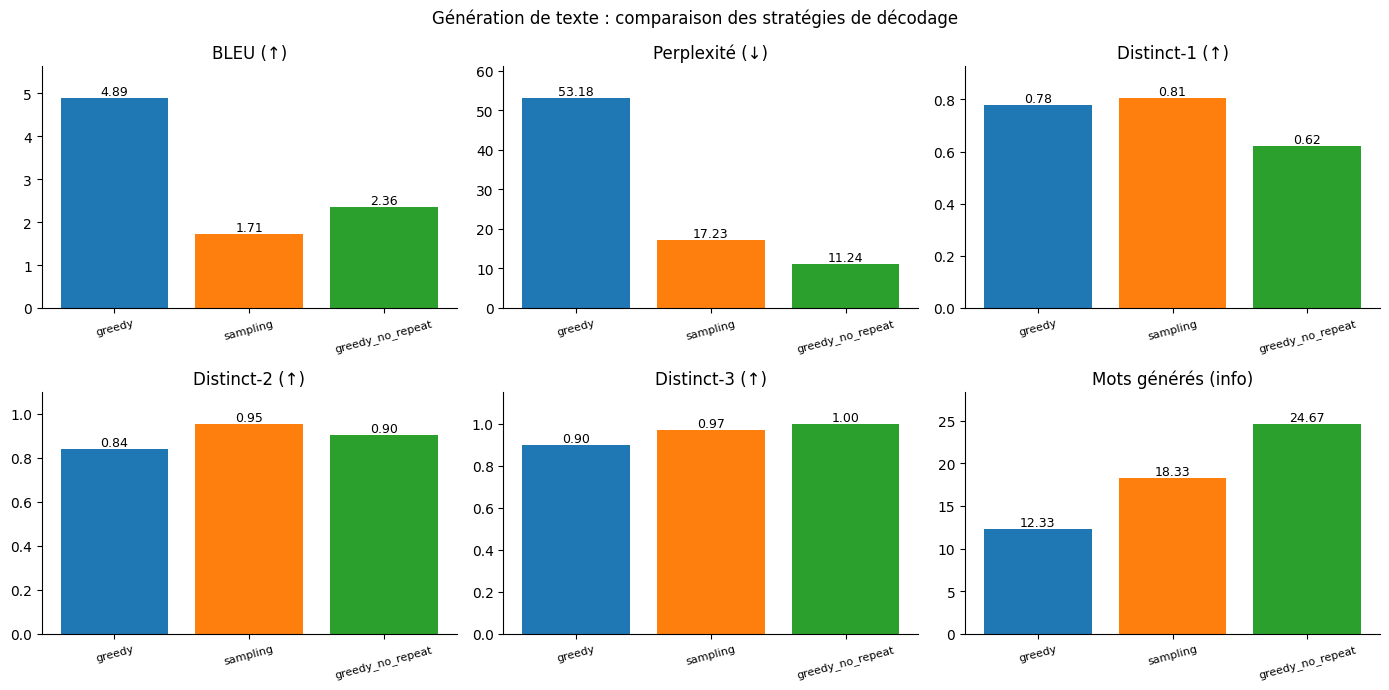

In [15]:
metric_titles = {
    "bleu": "BLEU (↑)",
    "perplexity": "Perplexité (↓)",
    "distinct_1": "Distinct-1 (↑)",
    "distinct_2": "Distinct-2 (↑)",
    "distinct_3": "Distinct-3 (↑)",
    "mean_words": "Mots générés (info)",
}
strategies = list(gen_results.keys())
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown"][:len(strategies)]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (metric, title) in zip(axes.ravel(), metric_titles.items()):
    values = [gen_results[s][metric] for s in strategies]
    bars = ax.bar(range(len(strategies)), values, color=colors)
    ax.bar_label(bars, fmt="%.2f", fontsize=9)
    ax.set_xticks(range(len(strategies)))
    ax.set_xticklabels(strategies, fontsize=8, rotation=15)
    ax.set_title(title)
    ax.margins(y=0.15)
fig.suptitle("Génération de texte : comparaison des stratégies de décodage")
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "generation_strategies.png"), dpi=150, bbox_inches="tight")
plt.show()

### 5.2 Surprisal token par token : d'où vient la perplexité ?

La perplexité est une **moyenne** : elle cache où le modèle est « surpris ». Pour un prompt, on trace la **surprisal** (−log p, en nats) de chaque token généré, selon les trois stratégies.

On calcule aussi la perplexité de deux façons : sur les **tokens réellement générés**, et sur le **texte décodé puis re-tokenisé** (comme dans la métrique de la section 5). Si les deux valeurs diffèrent, la re-tokenisation modifie les tokens (typiquement les retours à la ligne répétés) et la perplexité « texte » est faussée.

In [16]:
SURPRISAL_PROMPT_IDX = 1    # prompt analysé (index dans GEN_PROMPTS)

def generate_ids(prompt, max_new_tokens=30, **gen_kwargs):
    """Comme generate_continuation, mais renvoie les ids des tokens (prompt, nouveaux tokens)."""
    inputs = gen_tokenizer(prompt, return_tensors="pt").to(DEVICE_STR)
    with torch.no_grad():
        output_ids = gen_model.generate(
            **inputs, max_new_tokens=max_new_tokens,
            pad_token_id=gen_tokenizer.eos_token_id, **gen_kwargs,
        )
    return inputs["input_ids"], output_ids[:, inputs["input_ids"].shape[1]:]

def surprisal_from_ids(prompt_ids, new_ids):
    """Surprisal (−log p, en nats) de chaque nouveau token sachant tout ce qui précède."""
    ids = torch.cat([prompt_ids.to(DEVICE_STR), new_ids.to(DEVICE_STR)], dim=1)
    with torch.no_grad():
        logits = gen_model(ids).logits
    log_probs = torch.log_softmax(logits[0, :-1].float(), dim=-1)      # prédictions des positions 1..L-1
    targets = ids[0, 1:]
    nll = -log_probs.gather(1, targets.unsqueeze(1)).squeeze(1)
    n_prompt = prompt_ids.shape[1]
    return nll[n_prompt - 1:].cpu().numpy()                             # uniquement les nouveaux tokens

trace = {}
prompt = GEN_PROMPTS[SURPRISAL_PROMPT_IDX]
for name, kwargs in STRATEGIES.items():
    set_seed(SEED)
    prompt_ids, new_ids = generate_ids(prompt, **kwargs)
    text = gen_tokenizer.decode(new_ids[0], skip_special_tokens=True)
    retok_ids = gen_tokenizer(text, add_special_tokens=False, return_tensors="pt")["input_ids"]
    trace[name] = {
        "text": text,
        "tokens": gen_tokenizer.convert_ids_to_tokens(new_ids[0]),
        "nll": surprisal_from_ids(prompt_ids, new_ids),
        "nll_text": surprisal_from_ids(prompt_ids, retok_ids) if retok_ids.shape[1] > 0 else np.array([]),
    }

print("Prompt :", repr(prompt))
for name, t in trace.items():
    print(f"  {name:<17}: {t['text']!r}")

Prompt : 'In the future, universities will'
  greedy           : ' have to decide whether to accept the idea of a new university, or whether to accept the idea of a new university.\n\n\n\n\n\n'
  sampling         : " have to rethink their plans to reduce their fees, because it is not clear how much fees they would pay. The universities' fees are already up for"
  greedy_no_repeat : ' have to decide whether to accept the idea of a new university, or whether to allow it to be used for research.\n\n\nThe University of'


,PPL (tokens générés),PPL (texte re-tokenisé),Tokens générés,Tokens re-tokenisés,% tokens retour ligne
Stratégie,,,,,
greedy,2.99,8.32,30,27,20.0
sampling,12.46,12.46,30,30,0.0
greedy_no_repeat,4.93,6.30,30,29,10.0


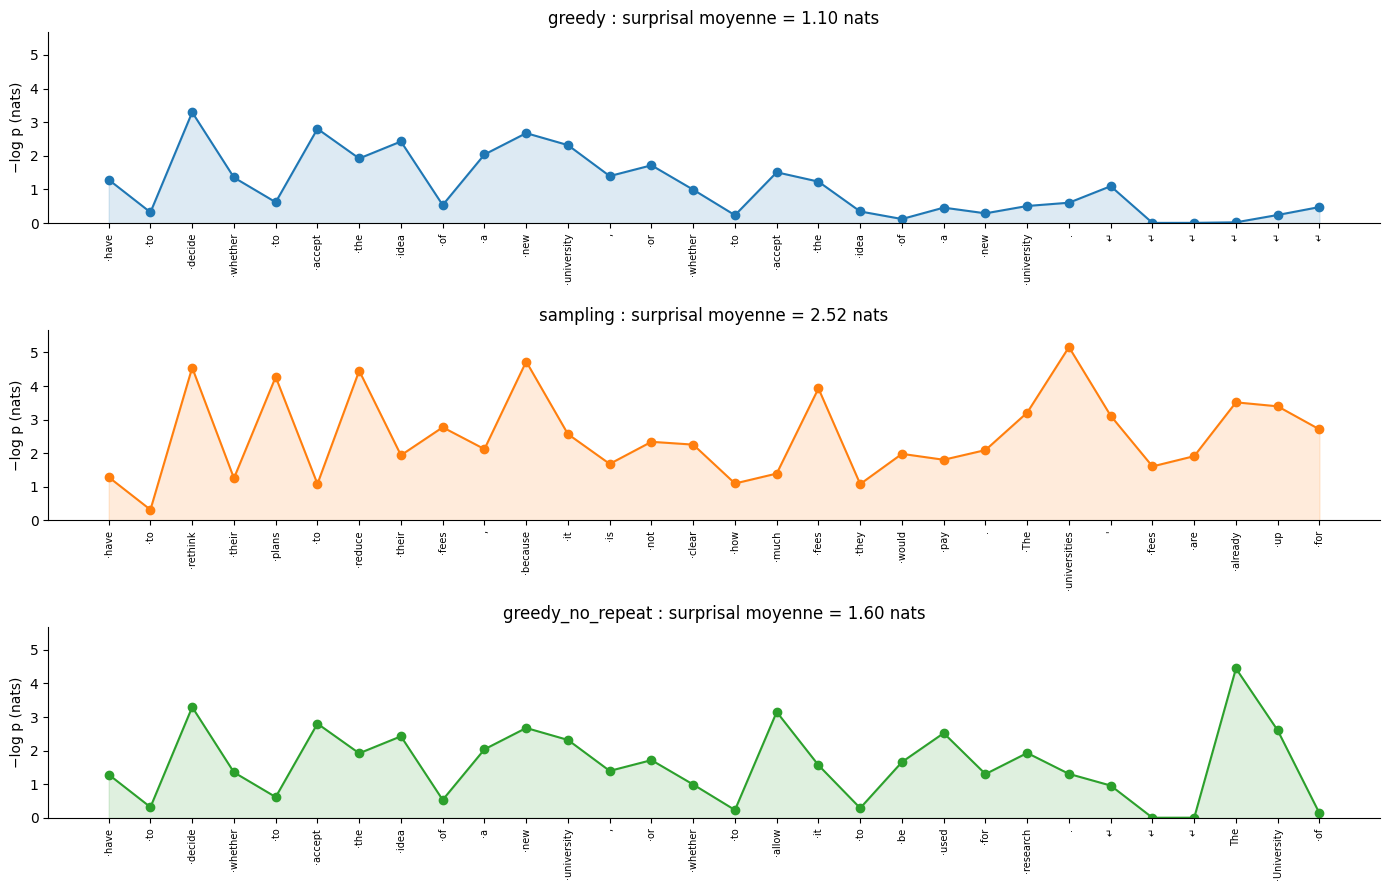

In [17]:
def pretty_token(tok):
    """Rend les tokens GPT-2 lisibles : · = espace initial, ↵ = retour à la ligne."""
    return tok.replace("Ġ", "·").replace("Ċ", "↵")

rows = []
for name, t in trace.items():
    rows.append({
        "Stratégie": name,
        "PPL (tokens générés)": float(np.exp(t["nll"].mean())),
        "PPL (texte re-tokenisé)": float(np.exp(t["nll_text"].mean())) if len(t["nll_text"]) else float("nan"),
        "Tokens générés": len(t["nll"]),
        "Tokens re-tokenisés": len(t["nll_text"]),
        "% tokens retour ligne": 100 * float(np.mean(["Ċ" in tok for tok in t["tokens"]])),
    })
display(pd.DataFrame(rows).set_index("Stratégie").round(2))

ymax = max(float(t["nll"].max()) for t in trace.values()) * 1.1
line_colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown"]
fig, axes = plt.subplots(len(trace), 1, figsize=(14, 3.0 * len(trace)), squeeze=False)
for ax, (name, t), color in zip(axes[:, 0], trace.items(), line_colors):
    x = np.arange(len(t["nll"]))
    ax.plot(x, t["nll"], marker="o", color=color, linewidth=1.5)
    ax.fill_between(x, t["nll"], alpha=0.15, color=color)
    ax.set_xticks(x)
    ax.set_xticklabels([pretty_token(tok) for tok in t["tokens"]], rotation=90, fontsize=7)
    ax.set_ylabel("−log p (nats)")
    ax.set_ylim(0, ymax)
    ax.set_title(f"{name} : surprisal moyenne = {t['nll'].mean():.2f} nats")
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "generation_surprisal.png"), dpi=150, bbox_inches="tight")
plt.show()

### 5.3 Robustesse : variabilité selon la graine et effet de la température

Une seule exécution de `sampling` ne prouve rien : le résultat change avec la **graine aléatoire**. On relance le sampling pour plusieurs températures et plusieurs graines (`top_p = 0.9`) et on affiche :

- **Boîtes à moustaches** de la perplexité et de Distinct-2 par température (chaque point noir = une graine). Les lignes pointillées donnent les stratégies **déterministes** (greedy, greedy_no_repeat) ;
- la **courbe de compromis** fluidité (perplexité) / diversité (Distinct-2).

⏱️ Environ 2 minutes sur CPU (`len(TEMPERATURES) × N_SEEDS × 3` générations).

In [18]:
TEMPERATURES = [0.3, 0.6, 0.8, 1.0, 1.3]
N_SEEDS = 5

def run_sampling_config(temperature, seed):
    """Génère pour tous les prompts avec une température et une graine données."""
    set_seed(seed)
    conts = [generate_continuation(p, do_sample=True, top_p=0.9, temperature=temperature) for p in GEN_PROMPTS]
    return {
        "bleu": sacrebleu.corpus_bleu(conts, [GEN_REFERENCES]).score,
        "perplexity": float(np.mean([perplexity(p + c) for p, c in zip(GEN_PROMPTS, conts)])),
        "distinct_2": float(np.mean([distinct_n(c, 2) for c in conts])),
    }

sweep_gen_rows = []
for T in TEMPERATURES:
    for seed in range(N_SEEDS):
        sweep_gen_rows.append({"temperature": T, "seed": seed, **run_sampling_config(T, seed)})
gen_sweep_df = pd.DataFrame(sweep_gen_rows)

display(gen_sweep_df.groupby("temperature")[["bleu", "perplexity", "distinct_2"]].agg(["mean", "std"]).round(3))

bleu        perplexity         distinct_2       
              mean    std       mean     std       mean    std
temperature                                                   
0.3          4.072  3.653     43.394  17.957      0.949  0.033
0.6          2.161  1.254     29.510  16.837      0.860  0.132
0.8          1.852  0.916     21.194  13.455      0.925  0.065
1.0          1.476  0.908     24.670  14.664      0.980  0.017
1.3          2.097  1.273     30.117   6.052      0.979  0.025

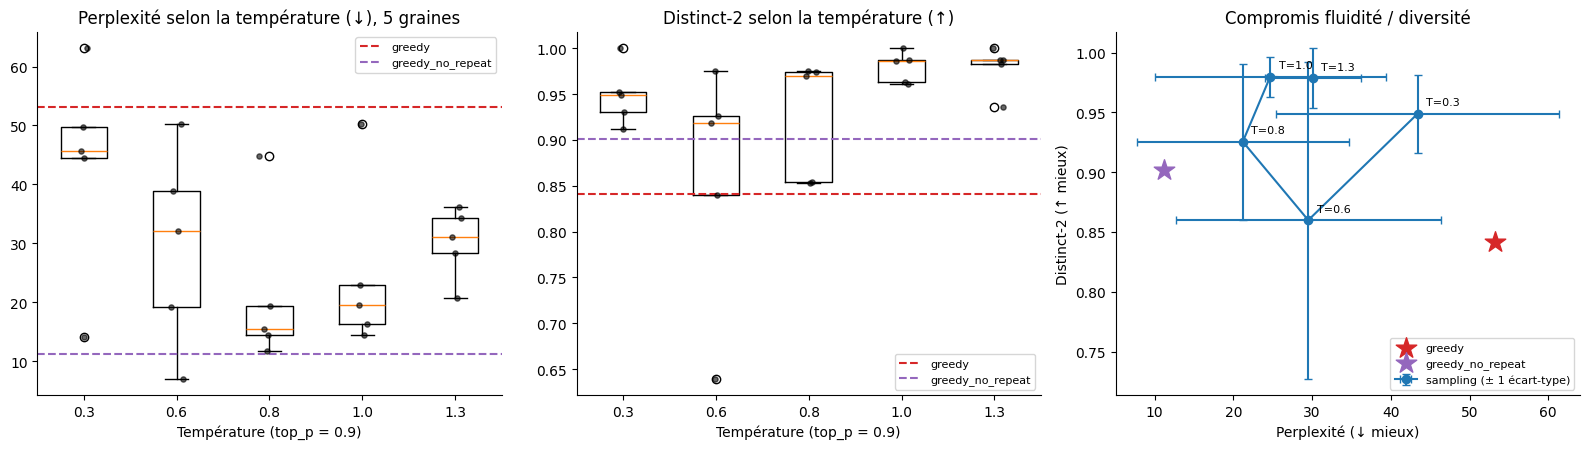

In [19]:
rng = np.random.default_rng(0)
ref_colors = {"greedy": "tab:red", "greedy_no_repeat": "tab:purple"}    # stratégies déterministes
agg = gen_sweep_df.groupby("temperature")[["perplexity", "distinct_2"]].agg(["mean", "std"])

def boxplot_by_temperature(ax, metric, title):
    data = [gen_sweep_df.loc[gen_sweep_df["temperature"] == T, metric].values for T in TEMPERATURES]
    ax.boxplot(data, widths=0.5)
    for k, values in enumerate(data, 1):
        ax.scatter(rng.normal(k, 0.05, len(values)), values, s=14, color="black", alpha=0.6, zorder=3)
    ax.set_xticks(range(1, len(TEMPERATURES) + 1))
    ax.set_xticklabels([str(T) for T in TEMPERATURES])
    ax.set_xlabel("Température (top_p = 0.9)")
    for name, color in ref_colors.items():
        if name in gen_results:
            ax.axhline(gen_results[name][metric], color=color, linestyle="--", linewidth=1.5, label=name)
    ax.set_title(title)
    ax.legend(fontsize=8)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.6))
boxplot_by_temperature(ax1, "perplexity", f"Perplexité selon la température (↓), {N_SEEDS} graines")
boxplot_by_temperature(ax2, "distinct_2", "Distinct-2 selon la température (↑)")

mx, ex = agg[("perplexity", "mean")], agg[("perplexity", "std")].fillna(0)
my, ey = agg[("distinct_2", "mean")], agg[("distinct_2", "std")].fillna(0)
ax3.errorbar(mx.values, my.values, xerr=ex.values, yerr=ey.values, marker="o", capsize=3,
             color="tab:blue", label="sampling (± 1 écart-type)")
for T in TEMPERATURES:
    ax3.annotate(f"T={T}", (mx.loc[T], my.loc[T]), textcoords="offset points", xytext=(6, 6), fontsize=8)
for name, color in ref_colors.items():
    if name in gen_results:
        ax3.scatter(gen_results[name]["perplexity"], gen_results[name]["distinct_2"],
                    marker="*", s=240, color=color, label=name, zorder=4)
ax3.set_xlabel("Perplexité (↓ mieux)")
ax3.set_ylabel("Distinct-2 (↑ mieux)")
ax3.set_title("Compromis fluidité / diversité")
ax3.legend(fontsize=8)

plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "generation_temperature.png"), dpi=150, bbox_inches="tight")
plt.show()

## 6. Temps de réponse et vitesse de chaque méthode

On mesure, pour chaque méthode, avec **une requête à la fois** (batch = 1) :

- **Latence (temps de réponse)** : durée d'un appel pour un exemple, en secondes (moyenne, écart-type, min, max).
- **Débit** : nombre d'**exemples traités par seconde** et de **tokens par seconde** (tokens *générés* pour le résumé et la génération, tokens *analysés* — question + contexte — pour le QA).
- **Temps de chargement** du modèle (mesuré lors du chargement, cellules précédentes).

**Méthodologie** : 1 appel de chauffe (*warm-up*) exclu de la mesure, puis `N_RUNS` répétitions par exemple, chronométrage avec `time.perf_counter()` et synchronisation CUDA si GPU (sinon le temps GPU asynchrone serait sous-estimé).

In [20]:
N_RUNS = 3    # répétitions chronométrées par exemple (augmentez pour une mesure plus stable)
WARMUP = 1    # appels de chauffe exclus de la mesure

HARDWARE = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print("Matériel :", HARDWARE)

def benchmark(label, inputs, run_one, count_tokens, token_kind):
    """Mesure la latence et le débit d'une méthode.

    inputs       : liste d'exemples
    run_one      : fonction(exemple) -> sortie
    count_tokens : fonction(exemple, sortie) -> nombre de tokens (générés ou analysés)
    token_kind   : "générés" ou "analysés" (pour documenter la colonne Tokens/s)

    Le résultat contient aussi "_per_item" : liste de (tokens moyens, latence moyenne) par exemple.
    """
    times, tokens, per_item = [], 0, []
    for item in inputs:
        for _ in range(WARMUP):
            run_one(item)
        item_times, item_tokens = [], []
        for _ in range(N_RUNS):
            sync()
            t0 = time.perf_counter()
            output = run_one(item)
            sync()
            item_times.append(time.perf_counter() - t0)
            item_tokens.append(count_tokens(item, output))
        times.extend(item_times)
        tokens += sum(item_tokens)
        per_item.append((float(np.mean(item_tokens)), float(np.mean(item_times))))
    total = sum(times)
    return {
        "Méthode": label,
        "Latence moy. (s)": float(np.mean(times)),
        "Écart-type (s)": float(np.std(times)),
        "Min (s)": float(np.min(times)),
        "Max (s)": float(np.max(times)),
        "Exemples/s": len(times) / total,
        "Tokens/s": tokens / total,
        "Type de tokens": token_kind,
        "_per_item": per_item,
    }

bench_rows = []
per_item_data = {}    # détail par exemple, utilisé pour le graphe latence vs tokens (6.2)

def add_benchmark(row, load_key):
    row["Chargement (s)"] = LOAD_TIMES[load_key]
    per_item_data[row["Méthode"]] = row.pop("_per_item")
    bench_rows.append(row)

# --- Résumé (1 article par appel) ---
add_benchmark(benchmark(
    "Résumé (DistilBART)",
    ARTICLES,
    lambda article: summarize([article])[0],
    lambda article, out: len(summarizer.tokenizer(out, add_special_tokens=False)["input_ids"]),
    "générés",
), "summarization")

# --- Question-Réponse (1 question par appel) ---
qa_inputs = [(ARTICLES[ctx_idx], question) for ctx_idx, question, _ in QA_SET]
add_benchmark(benchmark(
    "QA (DistilBERT)",
    qa_inputs,
    lambda cq: qa_pipeline(question=cq[1], context=cq[0])["answer"],
    lambda cq, out: len(qa_pipeline.tokenizer(cq[1], cq[0])["input_ids"]),
    "analysés",
), "qa")

# --- Génération : une ligne par stratégie de décodage ---
for strategy_name, strategy_kwargs in STRATEGIES.items():
    add_benchmark(benchmark(
        f"Génération {strategy_name} (DistilGPT-2)",
        GEN_PROMPTS,
        lambda prompt, kw=strategy_kwargs: generate_continuation(prompt, **kw),
        lambda prompt, out: len(gen_tokenizer(out, add_special_tokens=False)["input_ids"]),
        "générés",
    ), "generation")

bench_df = pd.DataFrame(bench_rows).set_index("Méthode")
bench_df.round(3)

Matériel : CPU


,Latence moy. (s),Écart-type (s),Min (s),Max (s),Exemples/s,Tokens/s,Type de tokens,Chargement (s)
Méthode,,,,,,,,
Résumé (DistilBART),7.383,1.235,5.511,9.098,0.135,6.456,générés,30.269
QA (DistilBERT),0.230,0.044,0.179,0.295,4.344,385.860,analysés,22.836
Génération greedy (DistilGPT-2),1.289,0.137,1.186,1.584,0.776,17.062,générés,17.517
Génération sampling (DistilGPT-2),1.407,0.087,1.338,1.583,0.711,18.722,générés,17.517
Génération greedy_no_repeat (DistilGPT-2),1.271,0.103,1.195,1.492,0.787,22.813,générés,17.517


### 6.1 Visualisation des temps de réponse et du débit

- **Gauche** : latence moyenne par appel (barres d'erreur = écart-type, échelle logarithmique car les méthodes peuvent différer d'un facteur 100).
- **Centre** : exemples traités par seconde (échelle logarithmique).
- **Droite** : tokens **générés** par seconde, uniquement pour les méthodes génératives (le QA analyse des tokens mais n'en génère pas).

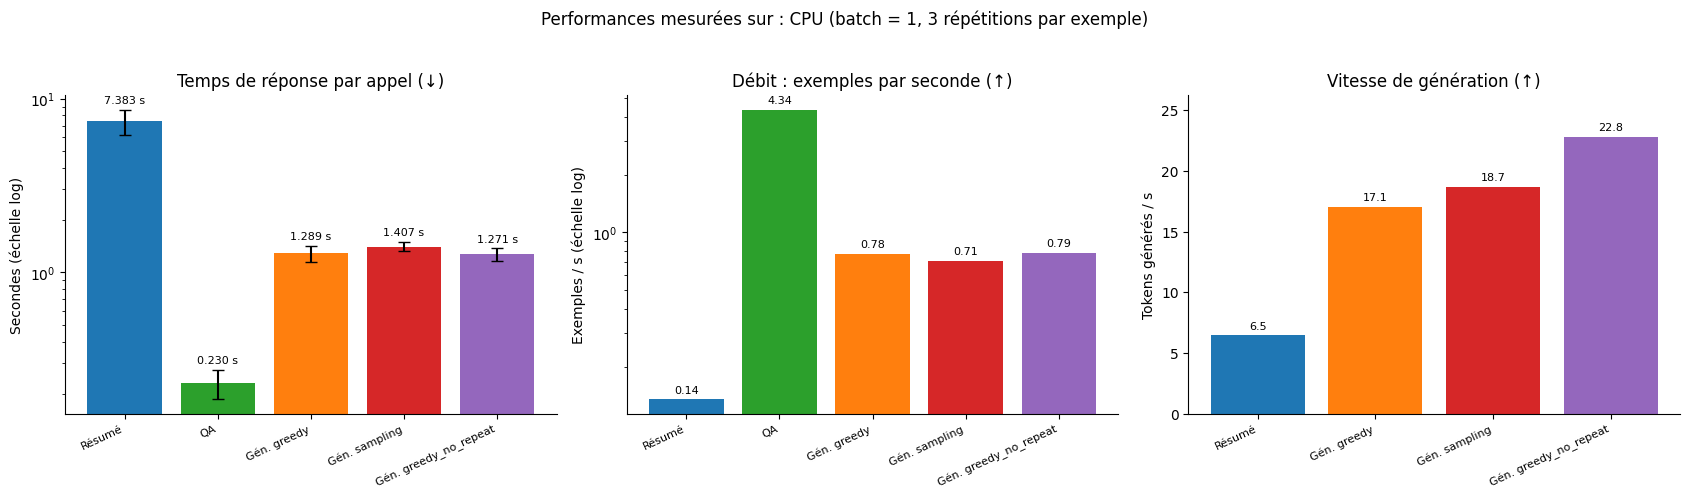

In [21]:
names = bench_df.index.tolist()
labels = [n.split(" (")[0].replace("Génération ", "Gén. ") for n in names]
colors = ["tab:blue", "tab:green", "tab:orange", "tab:red", "tab:purple", "tab:brown"][:len(names)]
x = np.arange(len(names))

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.8))

# (1) Latence moyenne ± écart-type
lat = bench_df["Latence moy. (s)"].values
std = bench_df["Écart-type (s)"].values
bars = ax1.bar(x, lat, yerr=std, capsize=4, color=colors)
ax1.set_yscale("log")
ax1.bar_label(bars, fmt="%.3f s", fontsize=8, padding=3)
ax1.set_xticks(x)
ax1.set_xticklabels(labels, fontsize=8, rotation=25, ha="right")
ax1.set_ylabel("Secondes (échelle log)")
ax1.set_title("Temps de réponse par appel (↓)")

# (2) Exemples / seconde
bars = ax2.bar(x, bench_df["Exemples/s"].values, color=colors)
ax2.set_yscale("log")
ax2.bar_label(bars, fmt="%.2f", fontsize=8, padding=3)
ax2.set_xticks(x)
ax2.set_xticklabels(labels, fontsize=8, rotation=25, ha="right")
ax2.set_ylabel("Exemples / s (échelle log)")
ax2.set_title("Débit : exemples par seconde (↑)")

# (3) Tokens générés / seconde (méthodes génératives uniquement)
gen_mask = (bench_df["Type de tokens"] == "générés").values
gx = np.arange(gen_mask.sum())
bars = ax3.bar(gx, bench_df.loc[gen_mask, "Tokens/s"].values,
               color=[c for c, m in zip(colors, gen_mask) if m])
ax3.bar_label(bars, fmt="%.1f", fontsize=8, padding=3)
ax3.set_xticks(gx)
ax3.set_xticklabels([l for l, m in zip(labels, gen_mask) if m], fontsize=8, rotation=25, ha="right")
ax3.set_ylabel("Tokens générés / s")
ax3.set_title("Vitesse de génération (↑)")
ax3.margins(y=0.15)

fig.suptitle(f"Performances mesurées sur : {HARDWARE} (batch = 1, {N_RUNS} répétitions par exemple)", y=1.03)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "performance_timing.png"), dpi=150, bbox_inches="tight")
plt.show()

### 6.2 Latence en fonction du nombre de tokens

Chaque point est un exemple (moyenne de ses répétitions). La droite est un ajustement linéaire par méthode. Pour les méthodes **génératives**, la latence croît avec le nombre de tokens générés (un passage du modèle par token) ; pour le **QA**, un seul passage suffit quelle que soit la réponse, la latence dépend de la longueur de l'entrée.

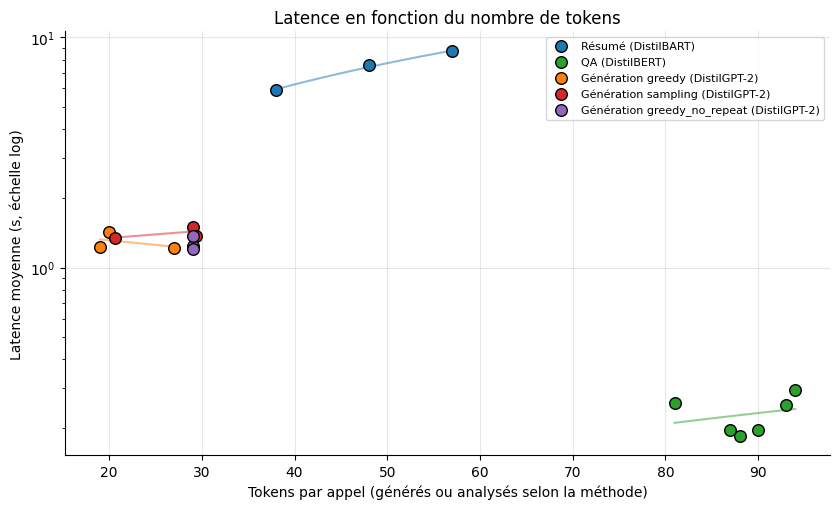

In [22]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
for (method, points), color in zip(per_item_data.items(), colors):
    xs = np.array([p[0] for p in points])
    ys = np.array([p[1] for p in points])
    ax.scatter(xs, ys, s=70, color=color, label=method, edgecolor="black", zorder=3)
    if len(set(xs.tolist())) > 1:
        slope, intercept = np.polyfit(xs, ys, 1)
        grid = np.linspace(xs.min(), xs.max(), 20)
        fit = slope * grid + intercept
        keep = fit > 0
        ax.plot(grid[keep], fit[keep], color=color, alpha=0.5)
ax.set_yscale("log")
ax.set_xlabel("Tokens par appel (générés ou analysés selon la méthode)")
ax.set_ylabel("Latence moyenne (s, échelle log)")
ax.set_title("Latence en fonction du nombre de tokens")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "performance_latency_vs_tokens.png"), dpi=150, bbox_inches="tight")
plt.show()

## 7. Tableau récapitulatif des résultats

In [23]:
rows = []
for k, v in rouge_results.items():
    rows.append({"Tâche": "Résumé", "Modèle": SUM_MODEL, "Métrique": k.upper(), "Score": round(v, 4)})
if bertscore_results:
    for k, v in bertscore_results.items():
        rows.append({"Tâche": "Résumé", "Modèle": "distilbert-base-uncased (BERTScore)", "Métrique": k, "Score": round(v, 4)})
for k, v in qa_results.items():
    rows.append({"Tâche": "Question-Réponse", "Modèle": QA_MODEL, "Métrique": k, "Score": round(v, 4)})
for strategy, metrics in gen_results.items():
    for k, v in metrics.items():
        rows.append({"Tâche": f"Génération ({strategy})", "Modèle": GEN_MODEL, "Métrique": k, "Score": round(v, 4)})

results_df = pd.DataFrame(rows)
results_df

,Tâche,Modèle,Métrique,Score
0,Résumé,sshleifer/distilbart-cnn-12-6,ROUGE1,0.4854
1,Résumé,sshleifer/distilbart-cnn-12-6,ROUGE2,0.1954
2,Résumé,sshleifer/distilbart-cnn-12-6,ROUGEL,0.3447
3,Résumé,distilbert-base-uncased (BERTScore),bertscore_precision,0.8345
4,Résumé,distilbert-base-uncased (BERTScore),bertscore_recall,0.8579
5,Résumé,distilbert-base-uncased (BERTScore),bertscore_f1,0.8460
6,Question-Réponse,distilbert-base-cased-distilled-squad,exact_match,0.5000
7,Question-Réponse,distilbert-base-cased-distilled-squad,f1,0.8345
8,Question-Réponse,distilbert-base-cased-distilled-squad,inclusion_match,1.0000
9,Génération (greedy),distilgpt2,bleu,4.8928


### 7.1 Graphique récapitulatif

Toutes les métriques bornées entre 0 et 1 sur un même axe (BLEU, sur 0–100, la perplexité, non bornée, et le nombre de mots sont exclus pour rester comparables).

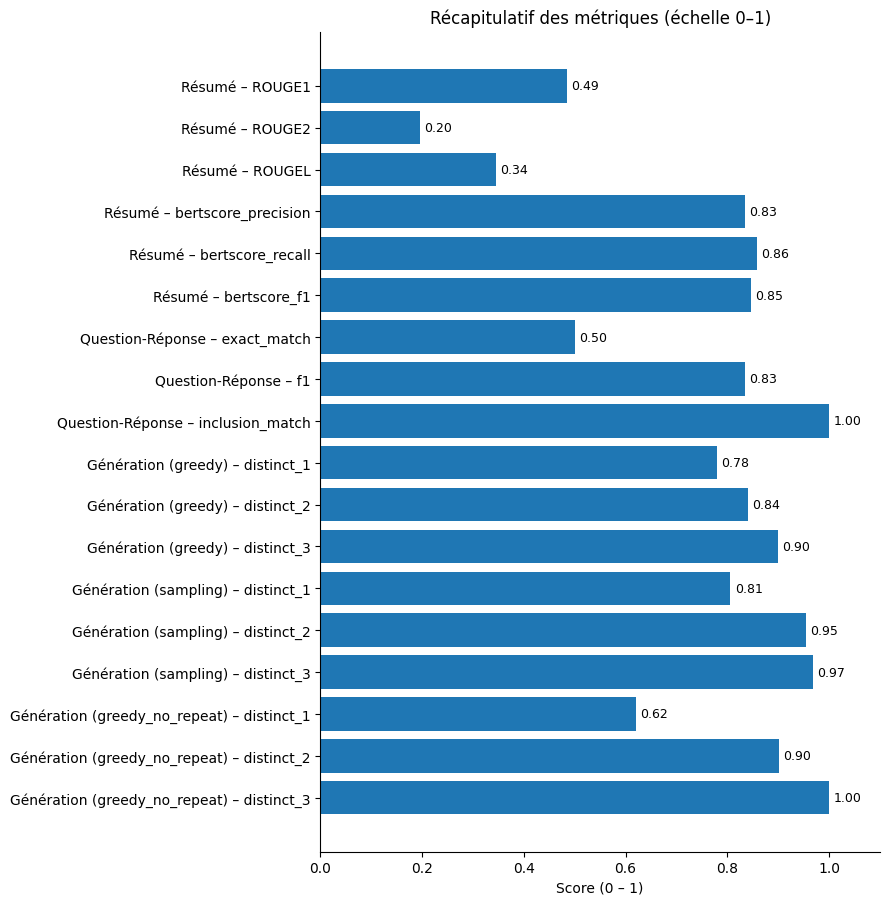

In [24]:
plot_df = results_df[~results_df["Métrique"].isin(["bleu", "perplexity", "mean_words"])].copy()
plot_df["Étiquette"] = plot_df["Tâche"] + " – " + plot_df["Métrique"]

fig, ax = plt.subplots(figsize=(9, 0.42 * len(plot_df) + 1.6))
bars = ax.barh(plot_df["Étiquette"], plot_df["Score"])
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
ax.set_xlim(0, 1.1)
ax.set_xlabel("Score (0 – 1)")
ax.set_title("Récapitulatif des métriques (échelle 0–1)")
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "summary_metrics.png"), dpi=150, bbox_inches="tight")
plt.show()

### 7.2 Synthèse automatique

Les phrases ci-dessous sont **calculées** à partir des résultats de cette exécution (elles se mettent à jour si vous changez les modèles ou les paramètres).

In [25]:
print("=== SYNTHÈSE (calculée à partir de cette exécution) ===\n")

print(f"Résumé     : ROUGE-1 = {rouge_results['rouge1']:.2f} | ROUGE-2 = {rouge_results['rouge2']:.2f} | ROUGE-L = {rouge_results['rougeL']:.2f}")
if bertscore_results:
    print(f"             BERTScore F1 = {bertscore_results['bertscore_f1']:.2f} (valeur brute, non rééchelonnée)")
truncated = [i + 1 for i, s in enumerate(summaries) if not is_complete(s)]
print("             résumés tronqués (max_length=60) :", truncated if truncated else "aucun")

n_boundary = int(qa_df["Erreur"].isin(["trop longue", "trop courte"]).sum())
n_wrong = int((qa_df["Erreur"] == "incorrecte").sum())
print(f"QA         : EM = {qa_results['exact_match']:.2f} | F1 = {qa_results['f1']:.2f} | inclusion = {qa_results['inclusion_match']:.2f}")
print(f"             erreurs de frontière : {n_boundary} | réponses incorrectes : {n_wrong}")

best_ppl = min(gen_results, key=lambda s: gen_results[s]["perplexity"])
best_div = max(gen_results, key=lambda s: gen_results[s]["distinct_3"])
print(f"Génération : perplexité la plus basse = {best_ppl} ({gen_results[best_ppl]['perplexity']:.1f}) | "
      f"Distinct-3 le plus haut = {best_div} ({gen_results[best_div]['distinct_3']:.2f})")
print(f"             (une seule graine : voir 5.3 pour la variabilité du sampling)")

fastest = bench_df["Latence moy. (s)"].idxmin()
slowest = bench_df["Latence moy. (s)"].idxmax()
ratio = bench_df.loc[slowest, "Latence moy. (s)"] / bench_df.loc[fastest, "Latence moy. (s)"]
print(f"Vitesse    : plus rapide = {fastest} ({bench_df.loc[fastest, 'Latence moy. (s)']:.2f} s) | "
      f"plus lente = {slowest} ({bench_df.loc[slowest, 'Latence moy. (s)']:.2f} s), soit ×{ratio:.0f}")

=== SYNTHÈSE (calculée à partir de cette exécution) ===

Résumé     : ROUGE-1 = 0.49 | ROUGE-2 = 0.20 | ROUGE-L = 0.34
             BERTScore F1 = 0.85 (valeur brute, non rééchelonnée)
             résumés tronqués (max_length=60) : [2]
QA         : EM = 0.50 | F1 = 0.83 | inclusion = 1.00
             erreurs de frontière : 3 | réponses incorrectes : 0
Génération : perplexité la plus basse = greedy_no_repeat (11.2) | Distinct-3 le plus haut = greedy_no_repeat (1.00)
             (une seule graine : voir 5.3 pour la variabilité du sampling)
Vitesse    : plus rapide = QA (DistilBERT) (0.23 s) | plus lente = Résumé (DistilBART) (7.38 s), soit ×32


## 8. Remarques et limites

- Le jeu de données est **volontairement minuscule** : les scores illustrent la méthode, ils ne constituent pas un benchmark. Pour des résultats significatifs, évaluez sur ≥ 500 exemples d'un dataset standard.
- **ROUGE / BLEU** mesurent un recouvrement lexical, pas le sens : deux phrases équivalentes mais reformulées obtiennent un score bas. **BERTScore** (section 3.3, similarité sémantique, modèle local) les complète ; ses valeurs brutes sont naturellement élevées : utilisez-le pour **comparer** des systèmes plutôt que comme score absolu.
- **EM** est strict, **F1** plus tolérant, le **match par inclusion** (section 4.2) encore plus indulgent : la comparaison des trois indique si les erreurs sont des erreurs de **frontière** (segment un peu trop long ou court) ou de vraies erreurs.
- Pour la génération, ne jugez pas sur **une seule métrique** : la perplexité seule ne détecte pas les répétitions, Distinct-n ignore les retours à la ligne, et la perplexité calculée sur le texte décodé peut différer de celle des tokens réellement générés (section 5.2). Les écarts mesurés sur 3 prompts et une graine ne sont pas significatifs : la section 5.3 montre la variabilité du sampling.
- Les modèles utilisés sont **petits** pour tourner sur CPU ; remplacez-les (`SUM_MODEL`, `QA_MODEL`, `GEN_MODEL`) par des versions plus grandes si vous avez un GPU.
- Les **temps de réponse** dépendent fortement du matériel (CPU vs GPU, nombre de cœurs) et de la longueur des textes : comparez les méthodes **entre elles sur la même machine**, pas avec des valeurs publiées ailleurs. Le temps de chargement d'un modèle inclut son téléchargement au premier lancement : relancez la cellule pour mesurer le chargement depuis le cache.